# Inspect one ROICaT cluster across recordings
Choose the **roicat** Python kernel, then run the cells in order. Change `CLUSTER_ID` to inspect another proposed cell.

Each panel shows one matched **run**, grouped in session order. Cyan marks the selected ROI on the saved mean image. Crops are centred independently on the ROI: these are **prepared input coordinates, not ROICaT-aligned images**. Similar-looking centred crops alone do not confirm a match; switch to full-FOV view to inspect location.

Uses local prepared inputs, so no SMB mount or tracking rerun is needed. Use prepared inputs from the same run as the results. Cluster IDs can change after rerunning ROICaT.

In [1]:
from pathlib import Path
import json
import math
import numpy as np
import pandas as pd
from scipy import sparse
import matplotlib.pyplot as plt

PROJECT = Path('/Users/megyoung/mini2p-preprocessing')
RESULTS = Path('/Volumes/behrens/meg/3x3_field_magnitude_bandit/derivatives/cohort-01/sub-03_id-MY_71_R/ses-roicat_date-20261011/outputs')
PREPARED = Path('/Volumes/behrens/meg/3x3_field_magnitude_bandit/derivatives/cohort-01/sub-03_id-MY_71_R/ses-roicat_date-20261011/inputs')

matches = pd.read_csv(RESULTS / 'roi_matches.csv')
manifest = json.loads((RESULTS / 'input_manifest.json').read_text())
prepared_manifest = json.loads((PREPARED / 'manifest.json').read_text())
if manifest['sessions'] != prepared_manifest['sessions']:
    raise ValueError('Results and prepared input manifests differ. Select the matching input folder.')
if manifest.get('manual_shifts') != prepared_manifest.get('manual_shifts'):
    raise ValueError('Results and inputs use different manual shifts.')
records = {r['index']: r for r in manifest['sessions']}
assigned = matches[matches.cluster_id >= 0]
coverage = (assigned.groupby('cluster_id').agg(
    n_runs=('session_index', 'nunique'), n_sessions=('session', 'nunique'))
    .sort_values(['n_runs', 'n_sessions'], ascending=False))
display(coverage.head(20))
print('Choose a cluster_id from the left-hand index above.')

,n_runs,n_sessions
cluster_id,,
389,68,16
570,68,16
617,68,16
620,68,16
627,68,16
666,68,16
693,68,16
475,67,16
544,67,16


Choose a cluster_id from the left-hand index above.


In [ ]:
# EDIT THESE SETTINGS, then run this cell and the plotting cell below.
CLUSTER_ID = 620  # Replace with a specific ID, e.g. 437
CROP_RADIUS = 30                    # Pixels either side of the ROI; None = full FOV
PANELS_PER_PAGE = 24
COLUMNS = 6
SAVE_FIGURES = False                # Optional PNG export

# Empty means show every run. Optional exclusions use full session names.
EXCLUDE_RUNS = set()
EXCLUDE_RUNS = {
     ('ses-216_date-20260730', 'run-03'),
     ('ses-216_date-20260730', 'run-07'),
    ('ses-221_date-20260804', 'run-01'),
    ('ses-225_date-20260810', 'run-03'),
}


Cluster 620: 61 runs across 16 sessions (61 ROIs).


,session,run,session_index,original_roi_id,cluster_id
174,ses-216_date-20260730,run-01,0,175,620
574,ses-216_date-20260730,run-02,1,155,620
1346,ses-216_date-20260730,run-04,3,149,620
2115,ses-216_date-20260730,run-06,5,144,620
2847,ses-217_date-20260731,run-01,7,171,620
...,...,...,...,...,...
27951,ses-230_date-20260817,run-03,63,348,620
28242,ses-230_date-20260817,run-04,64,199,620
28661,ses-231_date-20260818,run-01,65,152,620
29030,ses-231_date-20260818,run-02,66,172,620


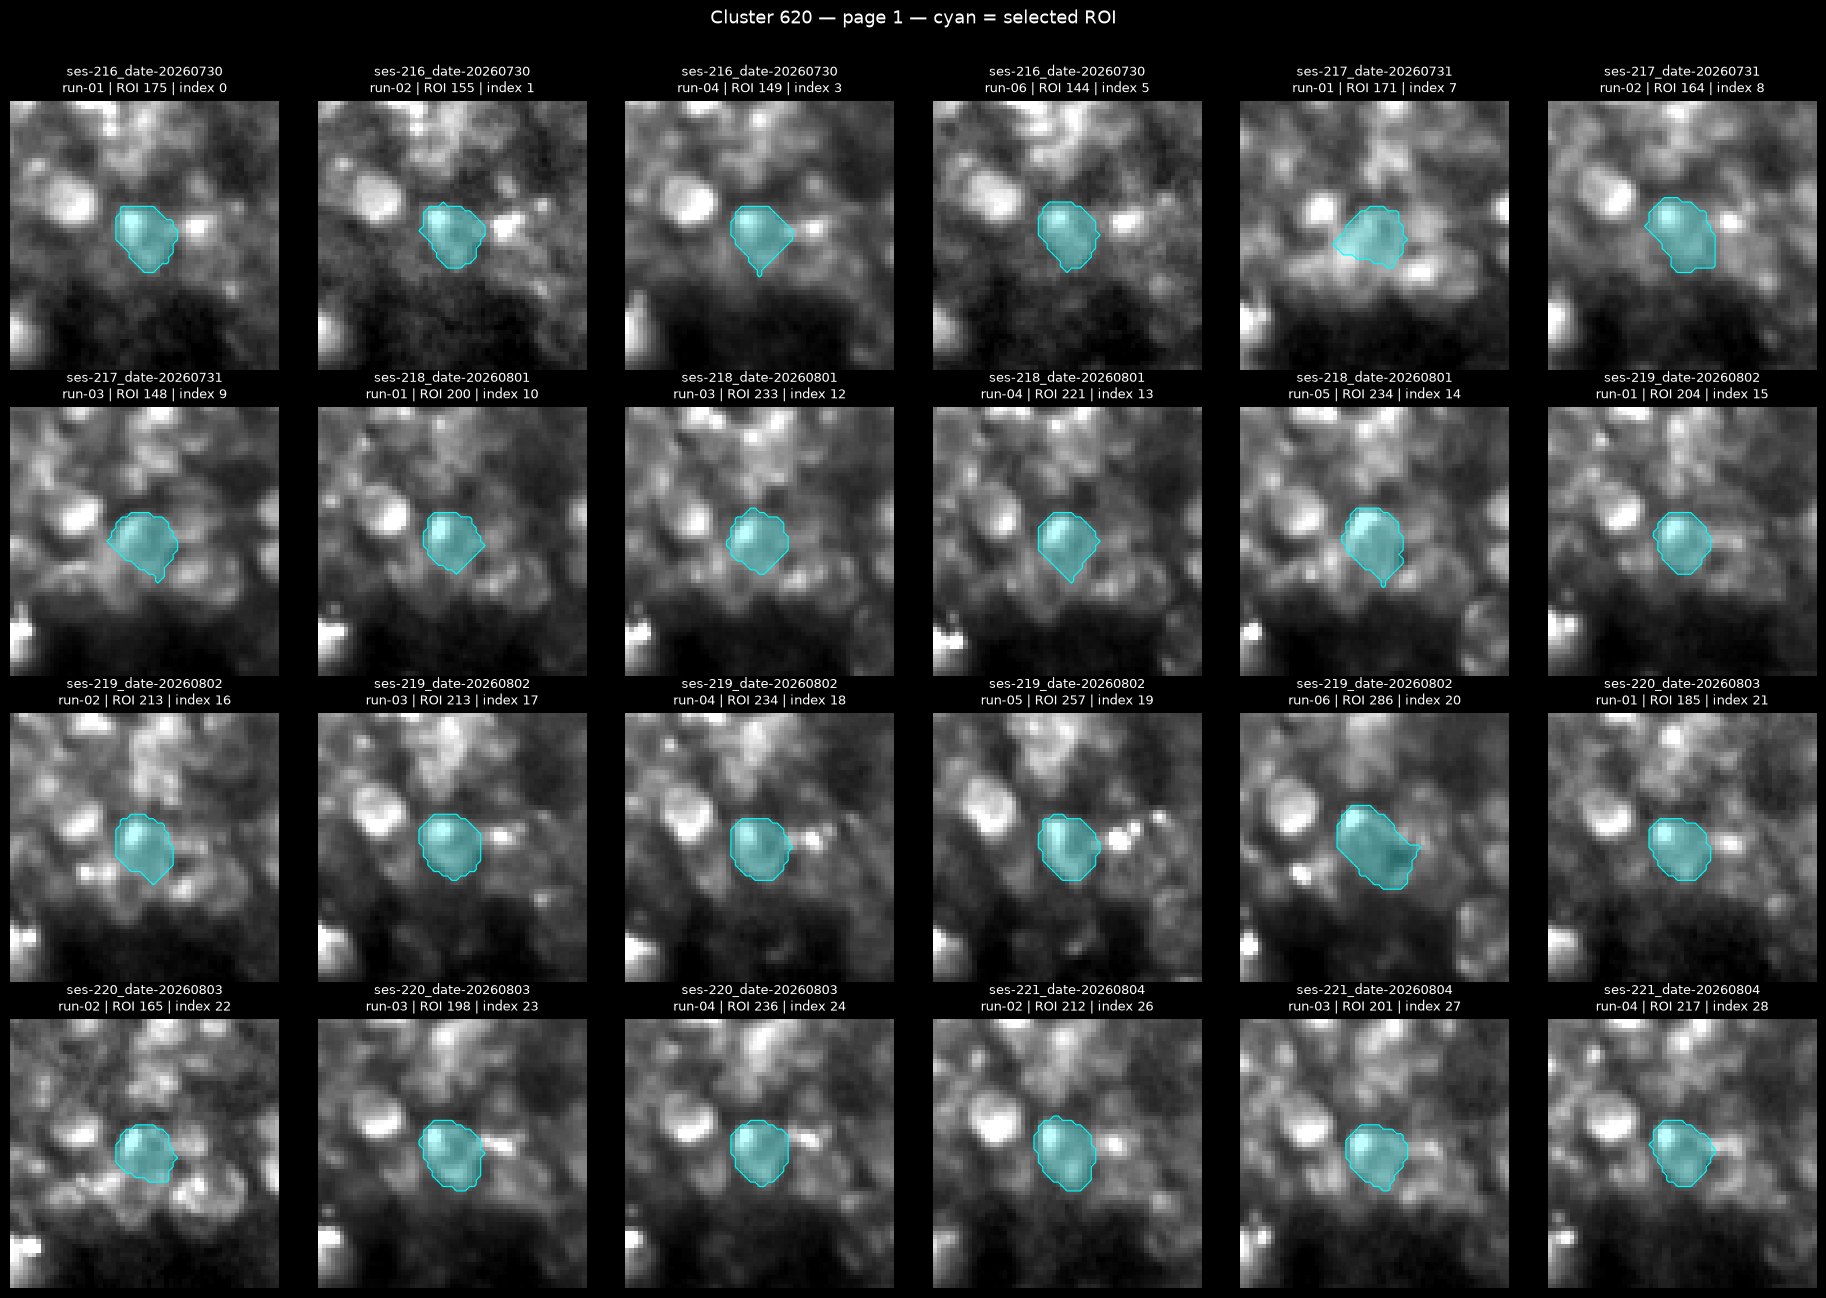

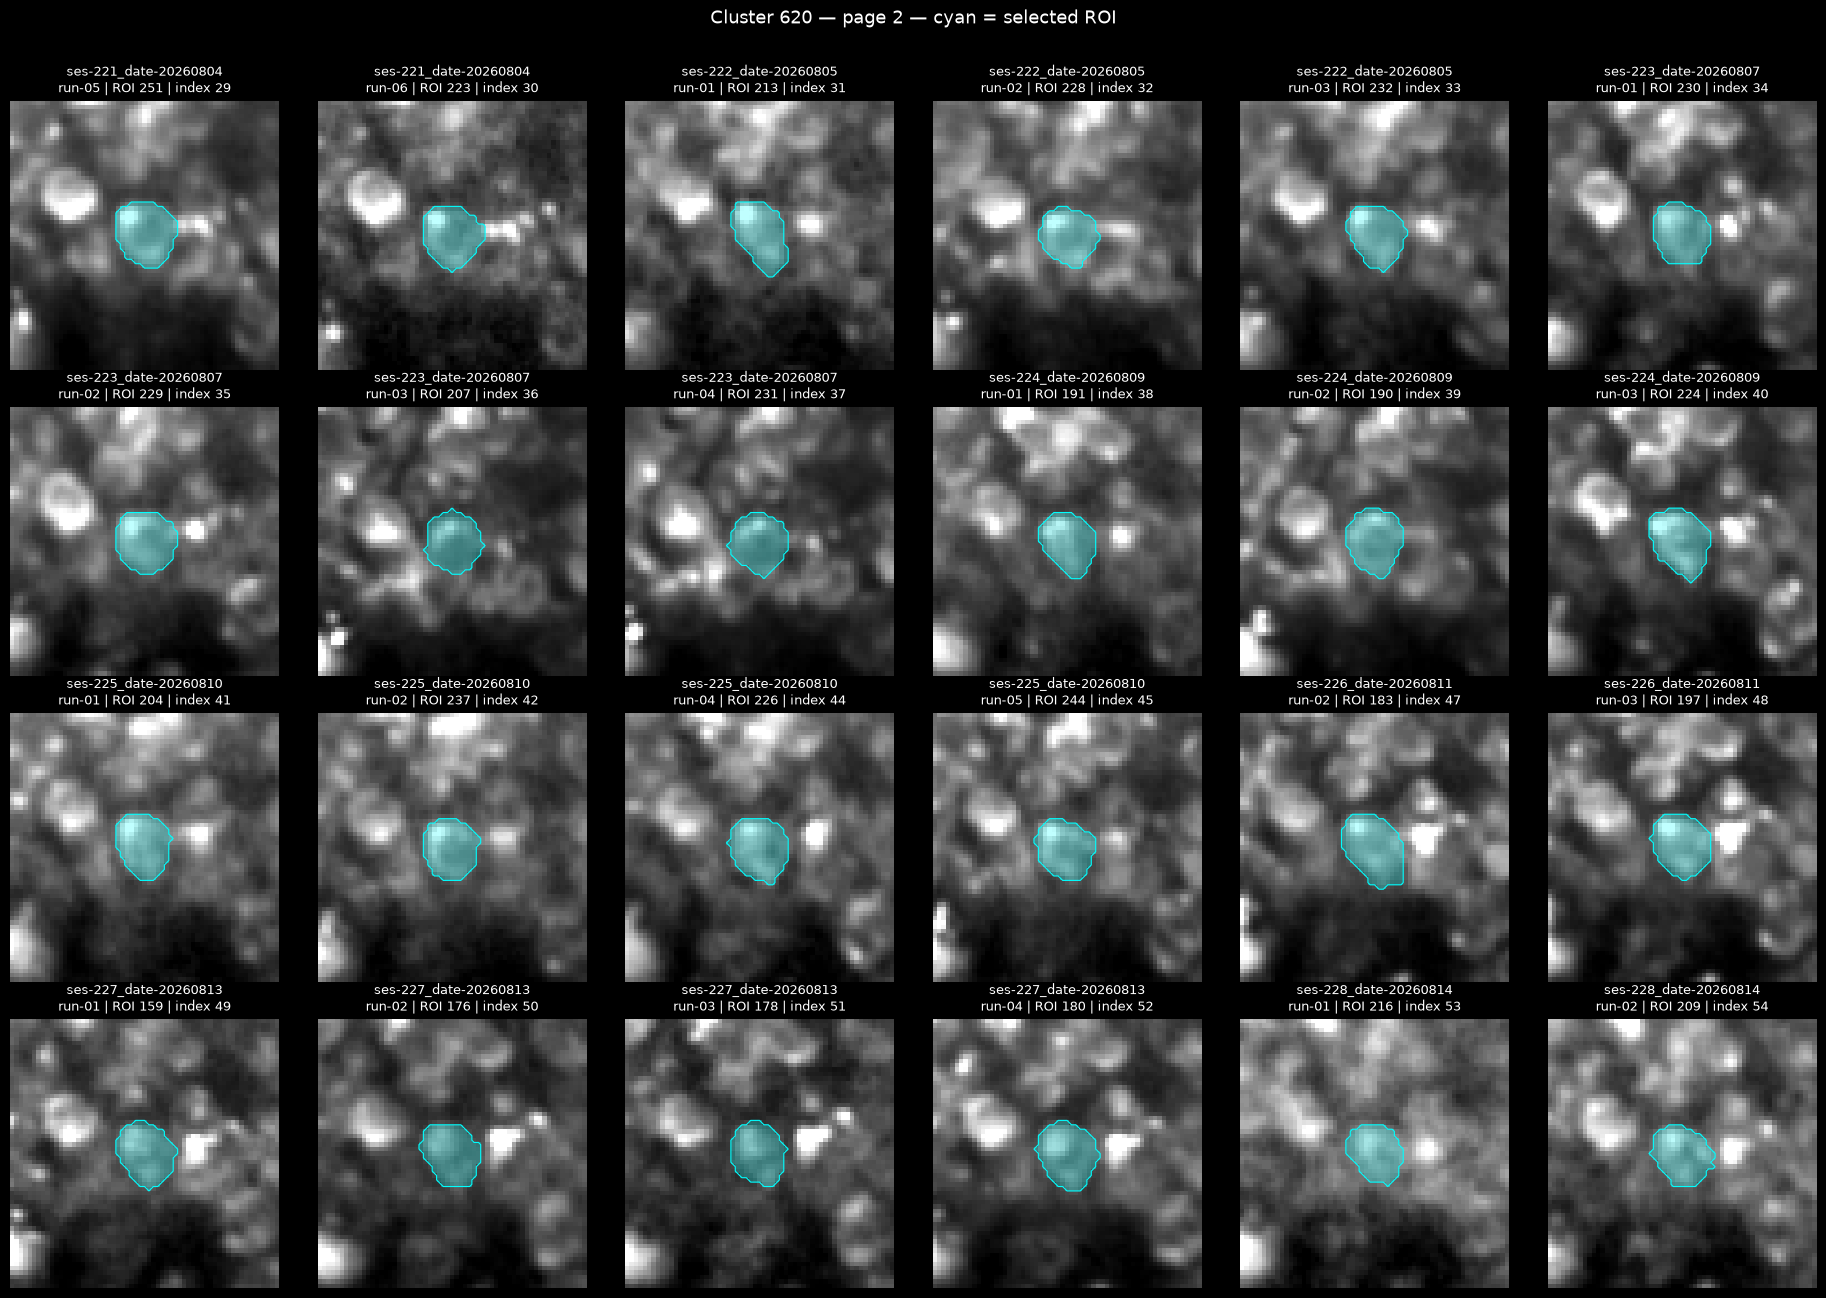

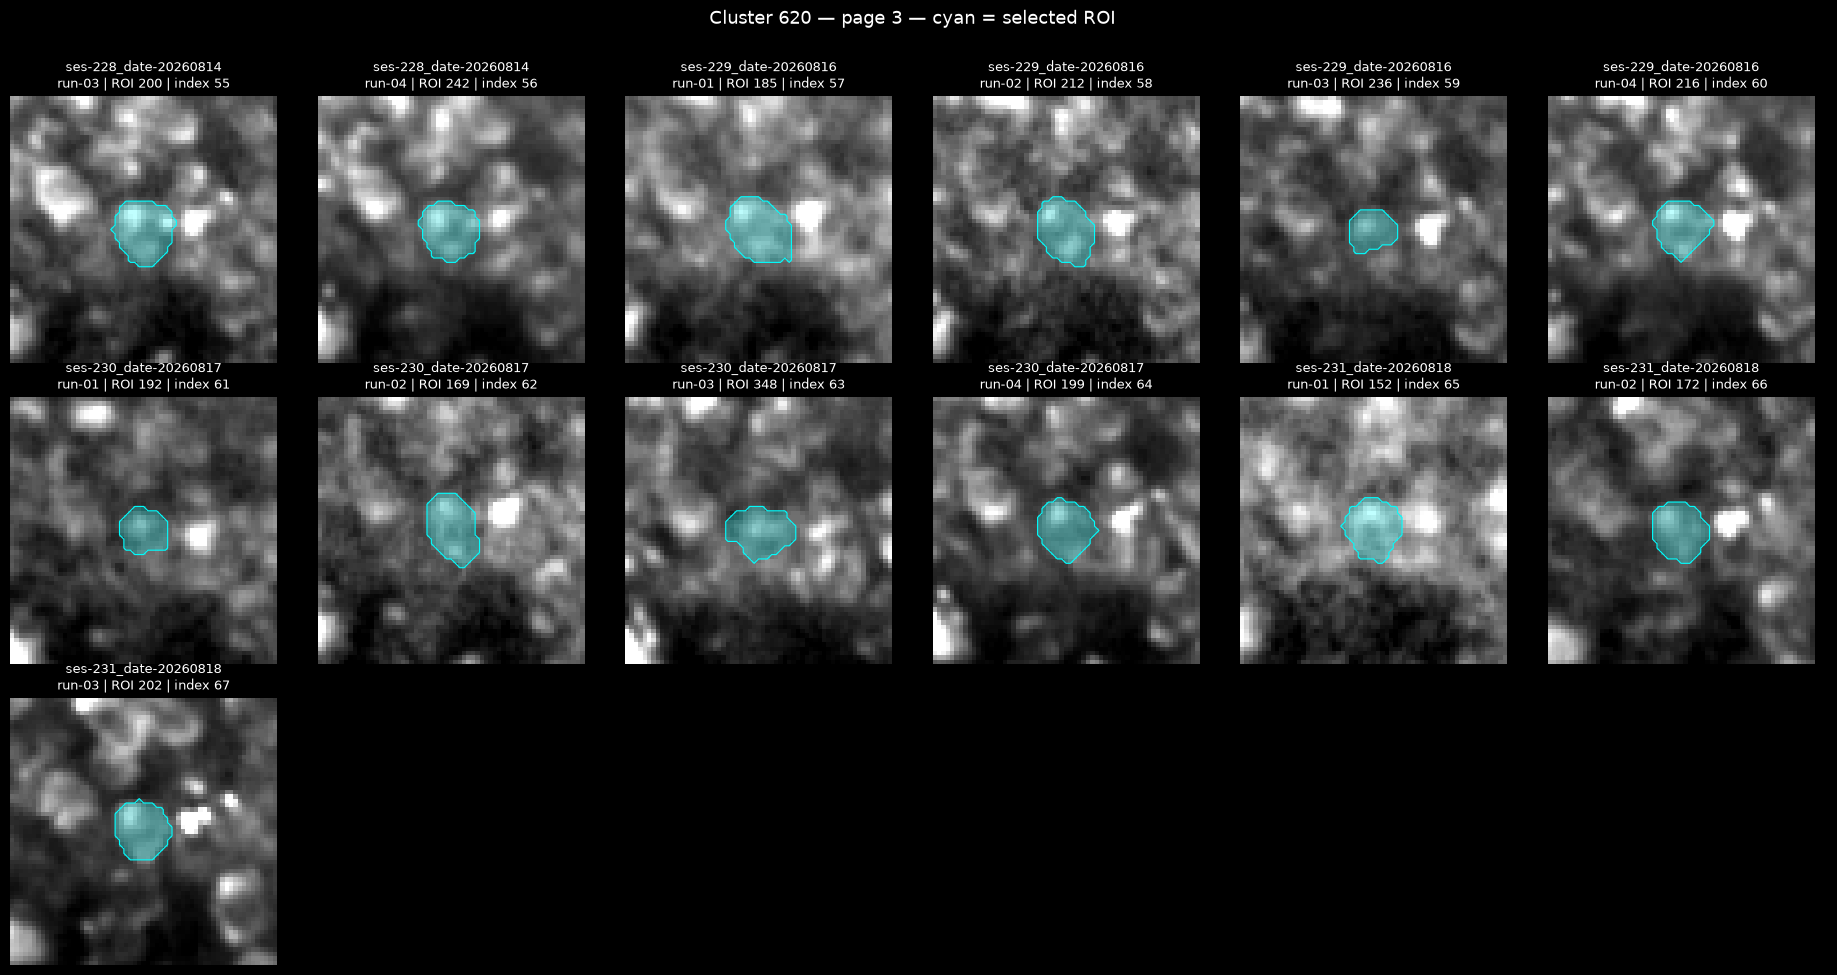

In [13]:
def plot_cluster(cluster_id):
    if cluster_id < 0:
        raise ValueError('-1 means unassigned, not a shared cell identity.')
    if CROP_RADIUS is not None and CROP_RADIUS < 1:
        raise ValueError('CROP_RADIUS must be positive or None.')
    if PANELS_PER_PAGE < 1 or COLUMNS < 1:
        raise ValueError('Page size and columns must be positive.')
    selected = matches[matches.cluster_id == cluster_id].copy()
    selected = selected[[ (s, r) not in EXCLUDE_RUNS
                          for s, r in zip(selected.session, selected.run) ]]
    selected = selected.sort_values(['session_index', 'roi_index'])
    if selected.empty:
        raise ValueError(f'No matches remain for cluster {cluster_id}.')
    print(f'Cluster {cluster_id}: {selected.session_index.nunique()} runs across '
          f'{selected.session.nunique()} sessions ({len(selected)} ROIs).')
    if selected.session_index.duplicated().any():
        print('Note: multiple ROIs share this cluster within a run; inspect carefully.')
    display(selected[['session', 'run', 'session_index', 'original_roi_id', 'cluster_id']])
    for start in range(0, len(selected), PANELS_PER_PAGE):
        page = selected.iloc[start:start + PANELS_PER_PAGE]
        cols = min(COLUMNS, len(page))
        fig, axes = plt.subplots(math.ceil(len(page) / cols), cols,
            figsize=(3.1 * cols, 3.3 * math.ceil(len(page) / cols)), squeeze=False)
        fig.patch.set_facecolor('black')
        for ax in axes.flat:
            ax.axis('off')
        for ax, row in zip(axes.flat, page.itertuples()):
            i, j = int(row.session_index), int(row.roi_index)
            rec = records[i]
            if (rec['session'] != row.session or rec['run'] != row.run
                    or rec['roi_ids'][j] != row.original_roi_id):
                raise ValueError(f'ROI identity mismatch at recording {i}, row {j}.')
            image = np.load(PREPARED / f'fov_{i:03d}.npy', allow_pickle=False)
            footprints = sparse.load_npz(PREPARED / f'footprints_{i:03d}.npz').tocsr()
            if footprints.shape != (rec['n_rois'], image.size):
                raise ValueError(f'Footprint dimensions mismatch at recording {i}.')
            roi = footprints.getrow(j).toarray().reshape(image.shape)
            yy, xx = np.where(roi > 0)
            if not len(xx):
                raise ValueError(f'Empty ROI at recording {i}, row {j}.')
            if CROP_RADIUS is None:
                x0, x1, y0, y1 = 0, image.shape[1], 0, image.shape[0]
            else:
                cx, cy = int(round(xx.mean())), int(round(yy.mean()))
                radius = int(CROP_RADIUS)
                x0, x1 = max(0, cx-radius), min(image.shape[1], cx+radius+1)
                y0, y1 = max(0, cy-radius), min(image.shape[0], cy+radius+1)
            crop = image[y0:y1, x0:x1]
            mask = roi[y0:y1, x0:x1] > 0
            lo, hi = np.percentile(crop, [1, 99])
            ax.imshow(crop, cmap='gray', vmin=lo, vmax=hi if hi > lo else lo+1)
            tint = np.zeros((*mask.shape, 4))
            tint[mask] = [0, 1, 1, .25]
            ax.imshow(tint)
            # Explicit pixel centres keep the outline in the same coordinates as imshow.
            ax.contour(np.arange(-1, mask.shape[1] + 1),
                       np.arange(-1, mask.shape[0] + 1),
                       np.pad(mask.astype(float), 1), levels=[.5],
                       colors=['cyan'], linewidths=.8)
            ax.set_xlim(-.5, crop.shape[1]-.5)
            ax.set_ylim(crop.shape[0]-.5, -.5)
            ax.set_title(f'{row.session}\n{row.run} | ROI {row.original_roi_id} | index {i}', fontsize=9,
                         color='white')
        page_number = start // PANELS_PER_PAGE + 1
        fig.suptitle(f'Cluster {cluster_id} — page {page_number} — cyan = selected ROI', fontsize=13,
                     color='white')
        fig.tight_layout(rect=(0, 0, 1, .97))
        if SAVE_FIGURES:
            out = RESULTS / 'cluster_inspection'
            out.mkdir(exist_ok=True)
            fig.savefig(out / f'cluster_{cluster_id}_page_{page_number}.png', dpi=180,
                        transparent=True)
        plt.show()
        plt.close(fig)
    return selected
 
selected_matches = plot_cluster(CLUSTER_ID)